<a href="https://colab.research.google.com/github/Avann21/238244-NguyenQuocHuy/blob/main/Ch%E1%BB%A7_%C4%91%E1%BB%81_3_H%E1%BB%87_th%E1%BB%91ng_%C4%90i%E1%BB%83m_danh_t%E1%BB%B1_%C4%91%E1%BB%99ng_qua_khu%C3%B4n_m%E1%BA%B7t_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Cài đặt môi trường**

In [ ]:
# ============================================================
# CELL 1: Cài đặt dependencies & tải shape predictor (Tối ưu cho cả Colab & Local Windows/Linux)
# ============================================================
import subprocess, sys, os
import urllib.request
import bz2

def _pip(*pkgs):
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *pkgs])

# dlib-bin = wheel dựng sẵn (Colab py3.12 linux) → không phải biên dịch dlib từ nguồn (~10 phút).
try:
    import dlib  # noqa: F401
except ImportError:
    try:
        _pip("dlib-bin")
        import dlib  # noqa: F401
    except Exception:
        print("⏳ Không có wheel dựng sẵn cho dlib — biên dịch từ nguồn. ĐỪNG disconnect trong lúc này.")
        _pip("cmake")          # fallback: biên dịch từ nguồn
        _pip("dlib")
        import dlib  # noqa: F401

# face_recognition khai báo phụ thuộc dlib → phải cài dlib trước, rồi mới cài package này
try:
    import face_recognition  # noqa: F401
except ImportError:
    _pip("face_recognition")

try:
    import cv2  # noqa: F401
except ImportError:
    _pip("opencv-python")

MODEL_FILE = "shape_predictor_68_face_landmarks.dat"
if not os.path.exists(MODEL_FILE):
    bz2_file = MODEL_FILE + ".bz2"
    url = "http://dlib.net/files/shape_predictor_68_face_landmarks.dat.bz2"
    print("⏳ Đang tải mô hình shape_predictor_68_face_landmarks.dat.bz2...")
    try:
        urllib.request.urlretrieve(url, bz2_file)
        print("⏳ Đang giải nén mô hình...")
        with open(bz2_file, "rb") as source, open(MODEL_FILE, "wb") as dest:
            dest.write(bz2.decompress(source.read()))
        if os.path.exists(bz2_file):
            os.remove(bz2_file)
    except Exception as e:
        print(f"⚠️ Thử tải qua urllib thất bại ({e}), dùng wget fallback...")
        subprocess.check_call(["wget", "-q", url])
        subprocess.check_call(["bunzip2", "-f", bz2_file])

print("✅ Môi trường sẵn sàng.")


⏳ Đang tải mô hình shape_predictor_68_face_landmarks.dat.bz2...
⏳ Đang giải nén mô hình...
✅ Môi trường sẵn sàng.


**Cấu hình tập trung**

In [ ]:
# ============================================================
# CELL 2: Cấu hình toàn hệ thống (single source of truth)
# ============================================================
from dataclasses import dataclass, field
from pathlib import Path

@dataclass(frozen=True)
class Config:
    """Toàn bộ tham số của hệ thống — không hard-code rải rác."""
    # Đường dẫn
    dataset_dir: Path = Path("dataset")
    database_path: Path = Path("known_faces.pkl")
    attendance_csv: Path = Path("attendance.csv")
    demo_image: Path = Path("demo_result.jpg")
    evidence_dir: Path = Path("evidence")     # ảnh gốc mỗi lượt điểm danh — bằng chứng đối chiếu

    # Model & detect
    detector_model: str = "hog"          # "hog" (CPU nhanh). pip dlib KHÔNG có CUDA → "cnn" vẫn chạy CPU, rất chậm
    embedding_dim: int = 128             # FaceNet output
    match_threshold: float = 0.45        # best_dist ≥ ngưỡng → người lạ
    match_margin: float = 0.06           # best phải cách rõ ràng so với ứng viên nhì (người khác) → chặn nhầm người giống nhau
    unknown_label: str = "Unknown"

    # Chống giả mạo (liveness) — Eye Aspect Ratio qua 68 landmarks
    blink_ear_closed: float = 0.23       # EAR nhỏ hơn mức này coi như mắt đang nhắm
    blink_ear_open: float = 0.27         # phải đạt mức này ở frame nào đó (phân biệt thật với ảnh tĩnh)

    # Quy định điểm danh
    cooldown_seconds: int = 86400        # 1 lượt/người/ngày (demo lặp lại cùng người → logger.reset_cooldown())
    min_images_per_student: int = 3      # mỗi SV nên có ≥3 ảnh nhiều góc/ánh sáng — build sẽ cảnh báo nếu ít hơn

    # Bounding box
    box_color_known: tuple = (0, 255, 0)     # BGR xanh lá
    box_color_unknown: tuple = (0, 0, 255)   # BGR đỏ
    box_thickness: int = 2
    font_scale: float = 0.6

CFG = Config()
print(f"⚙️ Cấu hình: threshold={CFG.match_threshold}, margin={CFG.match_margin}, "
      f"cooldown={CFG.cooldown_seconds}s (1 lượt/ngày), liveness=chớp mắt, detector={CFG.detector_model}")


⚙️ Cấu hình: threshold=0.45, margin=0.06, cooldown=86400s (1 lượt/ngày), liveness=chớp mắt, detector=hog


**(Tuỳ chọn) CELL 2b — Lưu dữ liệu vào Google Drive (không mất khi Colab reset)**

> Colab **xoá sạch** mọi file (`dataset/`, `known_faces.pkl`, `attendance.csv`) khi máy ảo reset.
> Bỏ comment các dòng dưới và chạy **sau CELL 2** nếu muốn dữ liệu sống sót qua các phiên.

In [ ]:
# ============================================================
# CELL 2b (TUỲ CHỌN): Mount Google Drive & trỏ CFG vào đó
# Bỏ comment và chạy SAU CELL 2 nếu muốn lưu dữ liệu bền vững.
# ============================================================
# from google.colab import drive
# drive.mount('/content/drive')
#
# _drive_dir = Path('/content/drive/MyDrive/face_attendance')
# _drive_dir.mkdir(parents=True, exist_ok=True)
#
# CFG = Config(
#     dataset_dir=_drive_dir / 'dataset',
#     database_path=_drive_dir / 'known_faces.pkl',
#     attendance_csv=_drive_dir / 'attendance.csv',
# )
# print(f"⚙️ Dữ liệu giờ lưu tại: {_drive_dir}")


** Lớp quản lý Database khuôn mặt**

In [ ]:
# ============================================================
# CELL 3: FaceDatabase — build / save / load / verify (with 68-landmark Alignment)
# ============================================================
import itertools
import pickle
import logging
from collections import defaultdict
from typing import List, Tuple
import numpy as np
import face_recognition
import dlib
import cv2
from pathlib import Path

logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")
log = logging.getLogger("attendance")

# 68-landmark predictor phục vụ Face Alignment
_predictor_path = "shape_predictor_68_face_landmarks.dat"
_sp = dlib.shape_predictor(_predictor_path) if Path(_predictor_path).exists() else None

def _check_similar_students(db: "FaceDatabase") -> list:
    """Cảnh báo các cặp sinh viên có embedding quá giống nhau (dễ nhận nhầm lẫn nhau) ngay lúc build DB."""
    by_name = defaultdict(list)
    for enc, name in zip(db.encodings, db.names):
        by_name[name].append(np.asarray(enc, dtype=np.float32))
    hits = []
    for a, b in itertools.combinations(sorted(by_name), 2):
        dmin = min(float(np.linalg.norm(x - y)) for x in by_name[a] for y in by_name[b])
        if dmin < CFG.match_threshold:
            hits.append((a, b, dmin))
            log.warning(
                "⚠️ Cặp sinh viên có đặc trưng quá gần nhau: '%s' ↔ '%s' (khoảng cách nhỏ nhất %.3f < %.2f) "
                "→ thêm ảnh phân biệt rõ (da góc, ánh sáng khác) hoặc kiểm tra lại tên thư mục.",
                a, b, dmin, CFG.match_threshold,
            )
    return hits

def align_face(image: np.ndarray, box) -> np.ndarray:
    """Căn chỉnh khuôn mặt thẳng bằng 68 landmarks.

    QUAN TRỌNG: phải dùng ở CẢ lúc build DB và CẢ lúc nhận diện —
    nếu bỏ align ở 1 phía, embedding hai phía lệch chuẩn → kết quả sai.
    """
    if _sp is None:
        # Bỏ align im lặng = encoding build vs nhận diện không cùng chuẩn → fail loud thay vì sai âm thầm
        raise RuntimeError(
            "Thiếu shape_predictor_68_face_landmarks.dat — hãy chạy lại CELL 1."
        )
    # Bounding box của face_recognition (top, right, bottom, left) → dlib.rectangle
    top, right, bottom, left = box
    rect = dlib.rectangle(left, top, right, bottom)
    shape = _sp(image, rect)
    return dlib.get_face_chip(image, shape, size=150)

class FaceDatabase:
    """
    Quản lý cơ sở dữ liệu embedding 128-D của sinh viên đã được căn chỉnh.
    """

    def __init__(self):
        self.encodings: List[np.ndarray] = []
        self.names: List[str] = []

    @classmethod
    def build(cls, dataset_dir: Path, detector: str = "hog") -> "FaceDatabase":
        db = cls()
        if not dataset_dir.is_dir():
            # Tạo thư mục mẫu nếu chưa tồn tại để tránh crash
            dataset_dir.mkdir(parents=True, exist_ok=True)
            log.warning(f"Đã tự động tạo thư mục {dataset_dir}. Vui lòng tải ảnh sinh viên vào thư mục con của nó.")

        valid_ext = {".jpg", ".jpeg", ".png"}
        skipped = 0
        per_person: dict = {}  # số embedding thu được theo từng sinh viên

        # Quét thư mục dataset/Ten_Sinh_Vien/anh.jpg (bỏ qua thư mục ẩn như .ipynb_checkpoints)
        for person_dir in sorted(dataset_dir.iterdir()):
            if not person_dir.is_dir() or person_dir.name.startswith("."):
                continue
            for img_path in sorted(person_dir.iterdir()):
                if img_path.suffix.lower() not in valid_ext:
                    continue
                try:
                    image = face_recognition.load_image_file(str(img_path))
                    locations = face_recognition.face_locations(image, model=detector)
                    if not locations:
                        log.warning("Bỏ qua (không detect mặt): %s", img_path.name)
                        skipped += 1
                        continue

                    # Lấy khuôn mặt lớn nhất — loc = (top, right, bottom, left)
                    largest_box = max(
                        locations,
                        key=lambda loc: (loc[2] - loc[0]) * (loc[1] - loc[3]),
                    )

                    # Căn chỉnh 68 điểm mốc trước khi trích xuất đặc trưng
                    aligned_img = align_face(image, largest_box)

                    # Embedding 128-D từ chip align 150x150 → box phủ toàn ảnh
                    encodings = face_recognition.face_encodings(aligned_img, known_face_locations=[(0, 150, 150, 0)])
                    if not encodings:
                        skipped += 1
                        continue

                    db.encodings.append(encodings[0])
                    db.names.append(person_dir.name)
                    per_person[person_dir.name] = per_person.get(person_dir.name, 0) + 1
                except Exception as e:
                    log.error("Lỗi xử lý file %s: %s", img_path.name, str(e))
                    skipped += 1

        # Cảnh báo sớm sinh viên ít embedding — nếu không sẽ "biến mất" khỏi hệ điểm danh
        for person in sorted(p.name for p in dataset_dir.iterdir() if p.is_dir() and not p.name.startswith(".")):
            n = per_person.get(person, 0)
            log.info("  SV %s: %d embedding", person, n)
            if n == 0:
                log.warning(
                    "⚠️ Sinh viên '%s' chưa có embedding nào (ảnh lỗi / không detect được mặt) "
                    "→ sẽ KHÔNG BAO GIỜ được điểm danh. Kiểm tra lại ảnh!",
                    person,
                )
            elif n < CFG.min_images_per_student:
                log.warning(
                    "⚠️ Sinh viên '%s' chỉ có %d embedding (khuyến nghị ≥ %d ảnh các góc/ánh sáng khác nhau) "
                    "→ dễ nhận sai khi nghiêng mặt hoặc đổi ánh sáng.",
                    person, n, CFG.min_images_per_student,
                )

        # Cảnh báo sớm: cặp sinh viên quá giống nhau sẽ bị nhận nhầm lẫn nhau khi chấm điểm danh
        _check_similar_students(db)

        if not db.encodings:
            log.warning("⚠️ Dataset chưa có ảnh hợp lệ nào. DB rỗng — mọi ảnh sẽ bị nhận là Unknown.")

        log.info(
            "Build DB: %d embedding / %d sinh viên (%d ảnh bị bỏ qua)",
            len(db.encodings), len(per_person), skipped,
        )
        if db.encodings:
            db.validate()
        return db

    def save(self, path: Path) -> None:
        if not self.encodings:
            log.warning("Database rỗng, không lưu file.")
            return
        with open(path, "wb") as f:
            pickle.dump((self.encodings, self.names), f)
        log.info("Đã lưu database → %s", path)

    @classmethod
    def load(cls, path: Path) -> "FaceDatabase":
        if not path.exists():
            raise FileNotFoundError(
                f"Chưa có {path}. Hãy chạy FaceDatabase.build(...) trước."
            )
        with open(path, "rb") as f:
            encodings, names = pickle.load(f)
        db = cls()
        db.encodings, db.names = encodings, names
        db.validate()
        log.info("Đã nạp DB: %d embedding / %d sinh viên",
                 len(db.encodings), len(set(db.names)))
        return db

    def validate(self) -> None:
        if not self.encodings or not self.names:
            raise ValueError("Database rỗng.")
        if len(self.encodings) != len(self.names):
            raise ValueError(
                f"Số encoding ({len(self.encodings)}) ≠ số tên ({len(self.names)})."
            )
        for i, enc in enumerate(self.encodings):
            if not isinstance(enc, np.ndarray):
                raise TypeError(f"Encoding [{i}] không phải numpy array.")
            if enc.shape != (CFG.embedding_dim,):
                raise ValueError(
                    f"Encoding [{i}] phải shape ({CFG.embedding_dim},), đang là {enc.shape}."
                )

    def __len__(self) -> int:
        return len(self.encodings)

    @property
    def unique_names(self) -> List[str]:
        return sorted(set(self.names))


/usr/local/lib/python3.13/dist-packages/face_recognition_models/__init__.py:7: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import resource_filename


**AttendanceLogger (ghi CSV + cooldown)**

In [ ]:
# ============================================================
# CELL 4: AttendanceLogger — ghi CSV an toàn + cooldown từng ngày
# ============================================================
import csv
from datetime import datetime, timedelta
from threading import Lock
from typing import Optional


class AttendanceLogger:
    """
    Ghi log điểm danh ra CSV, có cooldown chống ghi trùng.

    CSV lưu UTF-8 + BOM (utf-8-sig) → mở trong Excel hiện đúng tiếng Việt.
    Thread-safe nhờ Lock (phòng trường hợp mở rộng đa luồng sau này).
    """

    HEADER = ["Tên sinh viên", "Thời gian", "Khoảng cách Euclid", "Ảnh đối chiếu"]

    def __init__(self, csv_path: Path, cooldown_seconds: int = 86400):
        self.csv_path = csv_path
        self.cooldown = timedelta(seconds=cooldown_seconds)
        self._last_seen: dict[str, datetime] = {}
        self._lock = Lock()
        self._ensure_file()
        self._seed_cooldown_from_csv()

    def _ensure_file(self) -> None:
        if not self.csv_path.exists():
            with open(self.csv_path, "w", newline="", encoding="utf-8-sig") as f:
                csv.writer(f).writerow(self.HEADER)
            log.info("Đã tạo file %s", self.csv_path)
            return
        # File của phiên trước có thể còn header cũ (thiếu cột mới) → nâng cấp header, giữ nguyên dữ liệu cũ
        with open(self.csv_path, encoding="utf-8-sig", newline="") as f:
            rows = list(csv.reader(f))
        if rows and rows[0] != self.HEADER:
            with open(self.csv_path, "w", newline="", encoding="utf-8-sig") as f:
                w = csv.writer(f)
                w.writerow(self.HEADER)
                w.writerows(rows[1:])
            log.info("Đã cập nhật header %s (giữ %d dòng dữ liệu cũ)", self.csv_path, len(rows) - 1)

    def _seed_cooldown_from_csv(self) -> None:
        """Nạp cooldown ban đầu từ các điểm danh HÔM NAY trong CSV.

        Cooldown cũ chỉ nằm trong RAM → logger mới khi chạy lại cell có state rỗng
        và ghi dòng trùng ngay lập tức. Nạp từ CSV để chống được điều đó.
        """
        if not self.csv_path.exists():
            return
        today = datetime.now().strftime("%Y-%m-%d")
        try:
            with open(self.csv_path, encoding="utf-8-sig", newline="") as f:
                for row in csv.DictReader(f):
                    name = (row.get("Tên sinh viên") or "").strip()
                    ts = (row.get("Thời gian") or "").strip()
                    if name and ts.startswith(today):
                        try:
                            self._last_seen[name] = datetime.strptime(ts, "%Y-%m-%d %H:%M:%S")
                        except ValueError:
                            pass
        except OSError as e:
            log.warning("Không đọc được CSV để nạp cooldown: %s", e)

    def _in_cooldown(self, name: str, now: datetime) -> bool:
        last = self._last_seen.get(name)
        return last is not None and (now - last) < self.cooldown

    def try_log(self, name: str, distance: float, evidence: Optional[str] = None) -> bool:
        """
        Ghi điểm danh nếu chưa trong cooldown (mặc định: 1 lượt/người/ngày).

        evidence: đường dẫn ảnh chụp đối chiếu (tuỳ chọn).

        Returns
        -------
        bool
            True nếu đã ghi, False nếu bị bỏ qua do cooldown.
        """
        with self._lock:
            now = datetime.now()
            if self._in_cooldown(name, now):
                remaining = self.cooldown - (now - self._last_seen[name])
                log.info("⏳ %s đã điểm danh hôm nay (còn %.1fh) — bỏ qua.",
                         name, remaining.total_seconds() / 3600)
                return False

            # Ghi đuối bằng utf-8 thường — tránh chèn BOM giữa file (gotcha của utf-8-sig khi append)
            with open(self.csv_path, "a", newline="", encoding="utf-8") as f:
                csv.writer(f).writerow(
                    [name, now.strftime("%Y-%m-%d %H:%M:%S"), f"{distance:.4f}", evidence or ""]
                )
            self._last_seen[name] = now
            log.info("✅ Điểm danh: %s | distance=%.4f | ảnh=%s", name, distance, evidence or "—")
            return True

    def reset_cooldown(self, name: Optional[str] = None) -> None:
        """Reset cooldown cho 1 người (hoặc toàn bộ nếu name=None) — dùng khi demo lặp lại."""
        with self._lock:
            if name is None:
                self._last_seen.clear()
            else:
                self._last_seen.pop(name, None)


** FaceRecognizer (pipeline chính)**

In [ ]:
# ============================================================
# CELL 5: FaceRecognizer — liveness chớp mắt → detect → align 68 mốc → embed → match (margin)
# ============================================================
import cv2
import numpy as np
import face_recognition
import dlib
from datetime import datetime
from pathlib import Path
from typing import Optional, Sequence, Tuple, Union

# Chuẩn 68 điểm dlib: mắt trái = mốc 36-41, mắt phải = mốc 42-47
_EYE_IDS = (range(36, 42), range(42, 48))


class FaceRecognizer:
    """Pipeline thực tiễn: liveness chớp mắt → detect → align → 128-D → match (threshold + margin)."""

    def __init__(self, database: FaceDatabase, logger: AttendanceLogger, cfg: "Config | None" = None):
        self.db = database
        self.logger = logger
        # Resolve CFG lúc GỌI chứ không lúc định nghĩa class → Cell 5 chạy được kể cả trước Cell 2
        self.cfg = cfg if cfg is not None else CFG

    # ---------- so khớp ----------
    def _match(self, encoding: np.ndarray) -> Tuple[str, float]:
        """So khớp với DB. Nhận diện chỉ khi best < threshold VÀ cách rõ ràng so với ứng viên nhì."""
        if len(self.db) == 0:
            return self.cfg.unknown_label, 1.0

        distances = face_recognition.face_distance(self.db.encodings, encoding)
        if distances.size == 0:
            return self.cfg.unknown_label, 1.0

        best_idx = int(np.argmin(distances))
        best_dist = float(distances[best_idx])
        best_name = self.db.names[best_idx]

        if best_dist >= self.cfg.match_threshold:
            return self.cfg.unknown_label, best_dist

        # Ứng viên nhì PHẢI là người khác; nếu cách best không đủ xa → nhìn đồng dạng, từ chối để an toàn
        other_best = min(
            (d for d, n in zip(distances, self.db.names) if n != best_name),
            default=1.0,
        )
        if other_best - best_dist < self.cfg.match_margin:
            log.info(
                "🤔 Không rõ ràng: best=%.3f, người khác gần nhất=%.3f (margin tối thiểu %.3f) → coi là Unknown.",
                best_dist, other_best, self.cfg.match_margin,
            )
            return self.cfg.unknown_label, best_dist

        return best_name, best_dist

    # ---------- liveness ----------
    def _ear(self, image: np.ndarray, box) -> Optional[float]:
        """Eye Aspect Ratio qua 68 mốc (~0.25-0.35 khi mở, ~0.1 khi nhắm)."""
        if _sp is None:
            return None
        top, right, bottom, left = box
        rect = dlib.rectangle(left, top, right, bottom)
        shape = _sp(image, rect)
        pts = np.array([[shape.part(i).x, shape.part(i).y] for eye in _EYE_IDS for i in eye])
        ears = []
        for e in pts.reshape(2, 6, 2):
            width = np.linalg.norm(e[0] - e[3])
            height = (np.linalg.norm(e[1] - e[5]) + np.linalg.norm(e[2] - e[4])) / 2
            ears.append(height / width if width > 0 else 0.0)
        return min(ears)

    def check_liveness(self, frames: Sequence[np.ndarray]) -> Tuple[bool, int, str]:
        """Liveness bằng nhịp chớp mắt: chuỗi frame phải có ≥1 frame nhắm và ≥1 frame mở.

        Trả về (ok, index frame đẹp nhất để nhận diện, thông điệp).
        """
        ears: list = []
        box = None
        for f in frames:
            if box is None:
                # Detect CHỈ 1 LẦN: mặt gần như đứng yên trong vài giây chụp burst
                locs = face_recognition.face_locations(f, model=self.cfg.detector_model)
                if not locs:
                    ears.append(None)
                    continue
                box = max(locs, key=lambda loc: (loc[2] - loc[0]) * (loc[1] - loc[3]))
            # Các frame sau reuse box → chỉ chạy shape predictor (vài ms) thay vì HOG mỗi frame
            ears.append(self._ear(f, box))

        valid = [e for e in ears if e is not None]
        if len(valid) < 3:
            return False, 0, "Mặt không ổn định trong chuỗi chụp — nhìn thẳng camera, không che khuôn mặt."

        if min(valid) >= self.cfg.blink_ear_closed or max(valid) < self.cfg.blink_ear_open:
            return False, 0, (
                f"Không phát hiện nhịp chớp mắt (min EAR={min(valid):.2f}, max={max(valid):.2f}) — "
                "ảnh in/điện thoại cầm tĩnh sẽ bị từ chối. Hãy chớp mắt tự nhiên rồi chụp lại."
            )

        # Frame nhận diện = frame mắt mở rõ nhất (chất lượng embedding tốt nhất)
        best_idx = int(np.argmax([e if e is not None else -1.0 for e in ears]))
        return True, best_idx, f"Liveness OK — min EAR={min(valid):.2f}, max EAR={max(valid):.2f}"

    def _draw(self, image: np.ndarray, box, name: str, distance: Optional[float]) -> None:
        top, right, bottom, left = box
        H, W = image.shape[:2]
        top, bottom = max(0, top), min(H - 1, bottom)
        left, right = max(0, left), min(W - 1, right)

        if name != self.cfg.unknown_label:
            color = self.cfg.box_color_known
            label = f"{name} ({distance:.2f})"
        else:
            color = self.cfg.box_color_unknown
            label = "KHONG XAC DINH" if distance is None else f"KHONG XAC DINH ({distance:.2f})"

        cv2.rectangle(image, (left, top), (right, bottom), color, self.cfg.box_thickness)
        cv2.putText(
            image, label,
            (left, max(15, top - 8)),
            cv2.FONT_HERSHEY_SIMPLEX, self.cfg.font_scale, color, 2,
        )

    def _save_reject_frame(self, images: Sequence[np.ndarray], msg: str) -> Optional[Path]:
        """Vẽ khung đỏ lên frame có mặt (nếu có) và lưu ảnh demo — người dùng thấy rõ vì sao bị từ chối."""
        for f in images:
            locs = face_recognition.face_locations(f, model=self.cfg.detector_model)
            if locs:
                canvas = f.copy()
                box = max(locs, key=lambda loc: (loc[2] - loc[0]) * (loc[1] - loc[3]))
                self._draw(canvas, box, self.cfg.unknown_label, None)
                output = self.cfg.demo_image
                cv2.imwrite(str(output), cv2.cvtColor(canvas, cv2.COLOR_RGB2BGR))
                return output
        return None

    def process(self, frames: Union[str, Path, Sequence[Path]]) -> Optional[Path]:
        """
        Xử lý điểm danh.

        - Truyền 1 đường dẫn: chạy như cũ, KHÔNG có liveness (chỉ dùng để test ảnh tĩnh).
        - Truyền danh sách ≥2 frame (capture_burst): bắt buộc qua liveness;
          nhận diện trên frame mắt mở rõ nhất.
        """
        paths = [Path(frames)] if isinstance(frames, (str, Path)) else [Path(p) for p in frames]
        paths = [p for p in paths if p.exists()]
        if not paths:
            log.error("Không tìm thấy file ảnh nào.")
            return None

        images = [face_recognition.load_image_file(str(p)) for p in paths]

        if len(images) >= 2:
            ok, best_idx, msg = self.check_liveness(images)
            if not ok:
                log.warning("🛑 LIVENESS TỪ CHỐI: %s", msg)
                # Vẫn lưu + hiển thị ảnh khung đỏ để người dùng thấy lý do bị từ chối (CSV không ghi gì)
                return self._save_reject_frame(images, msg)
            log.info("👋 %s", msg)
        else:
            log.warning("⚠️ Chỉ có 1 frame — bỏ qua liveness. Khi chạy thực tế hãy dùng burst chụp (Cell 6/7).")
            best_idx = 0

        rgb = images[best_idx]
        locations = face_recognition.face_locations(rgb, model=self.cfg.detector_model)
        if not locations:
            log.warning("Không phát hiện khuôn mặt trong ảnh nhận diện.")
            return None

        canvas = rgb.copy()
        evidence_dir = Path(self.cfg.evidence_dir)
        evidence_dir.mkdir(parents=True, exist_ok=True)

        results = []
        for box in locations:
            aligned_face = align_face(rgb, box)
            encodings = face_recognition.face_encodings(aligned_face, known_face_locations=[(0, 150, 150, 0)])

            if encodings:
                encoding = encodings[0]
                name, distance = self._match(encoding)
                if name != self.cfg.unknown_label:
                    # Lưu frame gốc làm bằng chứng đối chiếu (camera thực sự nhìn thấy gì, không phải ảnh đã vẽ)
                    stamp = datetime.now().strftime("%Y%m%d_%H%M%S")
                    ev_path = evidence_dir / f"{stamp}_{name}.jpg"
                    cv2.imwrite(str(ev_path), cv2.cvtColor(rgb, cv2.COLOR_RGB2BGR))
                    if not self.logger.try_log(name, distance, str(ev_path)):
                        ev_path.unlink(missing_ok=True)  # cooldown → không có điểm danh → không cần bằng chứng
                else:
                    log.info("❓ %s | distance=%.4f", name, distance)
                results.append((box, name, distance))
            else:
                # Không encode được mặt này — vẫn phải hiện khung đỏ, không được bỏ im lặng
                log.warning("Không trích xuất được embedding cho 1 khuôn mặt — đánh dấu Unknown.")
                results.append((box, self.cfg.unknown_label, None))

        # Vẽ cho TẤT CẢ mặt đã detect: xanh = điểm danh hợp lệ, đỏ = KHONG XAC DINH
        for box, name, dist in results:
            self._draw(canvas, box, name, dist)

        output = self.cfg.demo_image
        cv2.imwrite(str(output), cv2.cvtColor(canvas, cv2.COLOR_RGB2BGR))
        log.info("Đã lưu ảnh demo → %s", output)
        return output


**Webcam Capture (JavaScript Colab)**

In [ ]:
# ============================================================
# CELL 6: WebcamCapture — Hỗ trợ cả Google Colab (Tab/Iframe) và Máy tính cục bộ (OpenCV)
# ============================================================
import glob, json, sys, threading, time
import http.server
import urllib.parse
from base64 import b64decode
from pathlib import Path
from typing import List
import cv2

try:
    from google.colab.output import serve_kernel_port_as_window, serve_kernel_port_as_iframe
except ImportError:
    serve_kernel_port_as_window = None
    serve_kernel_port_as_iframe = None

_PAGE_HTML = r"""<!doctype html>
<html>
<head><meta charset="utf-8"><title>Camera điểm danh</title></head>
<body style="font-family:sans-serif;text-align:center;background:#111;color:#eee;">
  <h3>📷 Hệ thống điểm danh khuôn mặt</h3>
  <video id="v" autoplay playsinline style="max-width:640px;border:2px solid #444;border-radius:8px;background:#000;"></video>
  <p id="st" style="font-size:16px;min-height:24px;">Đang xin quyền truy cập camera…</p>
  <button id="go" style="padding:12px 24px;font-size:17px;cursor:pointer;">📷 Bắt đầu điểm danh</button>

<script>
const COUNT = __COUNT__, INTERVAL = __INTERVAL__;
const v = document.getElementById('v');
const st = document.getElementById('st');
const btn = document.getElementById('go');
let stream = null;

(async () => {
  try {
    stream = await navigator.mediaDevices.getUserMedia({video: {width: 640, height: 480}});
  } catch (e) {
    st.textContent = '❌ Không mở được camera: ' + e.message;
    return;
  }
  v.srcObject = stream;
  st.textContent = '✅ Camera sẵn sàng — nhìn vào khung hình rồi bấm nút.';
})();

btn.onclick = async () => {
  if (!stream) { st.textContent = '❌ Camera chưa mở — tải lại trang (F5).'; return; }
  btn.disabled = true; btn.textContent = '⏳ Đang chụp...';
  await new Promise(r => setTimeout(r, 500)); // đợi ổn định sau khi bấm

  const frames = [];
  for (let i = 0; i < COUNT; i++) {
    st.textContent = `Đang chụp ${i + 1}/${COUNT} — NHÌN THẲNG CAMERA và CHỚP MẮT TỰ NHIÊN!`;
    const c = document.createElement('canvas');
    c.width = v.videoWidth; c.height = v.videoHeight;
    c.getContext('2d').drawImage(v, 0, 0);
    frames.push(c.toDataURL('image/jpeg', 0.9));
    await new Promise(r => setTimeout(r, INTERVAL));
  }

  st.textContent = 'Đang gửi ảnh về Colab…';
  try {
    const res = await fetch('/upload', {
      method: 'POST',
      headers: {'Content-Type': 'application/json'},
      body: JSON.stringify({frames: frames}),
    });
    const j = await res.json();
    if (j.ok) {
      st.textContent = '✅ Đã gửi! Kết quả sẽ hiện trong notebook Colab — có thể tắt tab này.';
      stream.getVideoTracks()[0].stop();
      setTimeout(() => { try { window.close(); } catch (e) {} }, 1500);
    } else {
      st.textContent = '⚠️ ' + (j.error || 'Gửi lỗi');
      btn.disabled = false; btn.textContent = '📷 Thử lại';
    }
  } catch (e) {
    st.textContent = '⚠️ Lỗi gửi ảnh: ' + e;
    btn.disabled = false; btn.textContent = '📷 Thử lại';
  }
};
</script>
</body>
</html>
"""

class _Handler(http.server.BaseHTTPRequestHandler):
    """GET /  → trang camera;  POST /upload → nhận burst frame và ghi ra file + flag."""

    def do_GET(self):
        q = urllib.parse.parse_qs(urllib.parse.urlparse(self.path).query)
        count = int(q.get("count", ["8"])[0])
        interval = int(q.get("interval", ["350"])[0])
        html = (_PAGE_HTML
                .replace("__COUNT__", str(count))
                .replace("__INTERVAL__", str(interval)))
        self._send(200, "text/html; charset=utf-8", html.encode("utf-8"))

    def do_POST(self):
        if self.path != "/upload":
            self._send(404, "text/plain", b"not found")
            return
        n = int(self.headers.get("Content-Length", 0) or 0)
        body = self.rfile.read(n)
        try:
            frames = json.loads(body)["frames"]
            if not isinstance(frames, list) or len(frames) < 3:
                raise ValueError("cần ít nhất 3 frame")
            for i, d in enumerate(frames):
                if not d or "," not in d:
                    raise ValueError("frame không hợp lệ")
                Path(f"burst_{i:02d}.jpg").write_bytes(b64decode(d.split(",", 1)[1]))
            Path("burst_flag.txt").write_text("ok", encoding="utf-8")  # đánh dấu xong SAU CÙNG
        except Exception as e:
            self._send(200, "application/json", json.dumps({"ok": False, "error": str(e)}).encode("utf-8"))
            return
        self._send(200, "application/json", json.dumps({"ok": True}).encode("utf-8"))

    def _send(self, code, ctype, data):
        self.send_response(code)
        self.send_header("Content-Type", ctype)
        self.send_header("Content-Length", str(len(data)))
        self.end_headers()
        self.wfile.write(data)

    def log_message(self, *a):
        pass  # không in log HTTP vào output

class WebcamCapture:
    """Hỗ trợ tự động: chạy Web Server trên Google Colab hoặc OpenCV Webcam trên máy tính cục bộ."""

    def capture_burst(self, count: int = 8, interval_ms: int = 350) -> List[Path]:
        # Dọn dẹp frame cũ
        for old in glob.glob("burst_*.jpg"):
            Path(old).unlink(missing_ok=True)
        Path("burst_flag.txt").unlink(missing_ok=True)

        # 1. Chạy trên Google Colab
        if serve_kernel_port_as_window is not None:
            state = getattr(sys, "_CAM_ATT", None)
            if state is None:
                httpd = http.server.ThreadingHTTPServer(("0.0.0.0", 0), _Handler)
                threading.Thread(target=httpd.serve_forever, daemon=True).start()
                state = {"server": httpd}
                sys._CAM_ATT = state
            port = state["server"].server_address[1]

            print("🌐 [Colab] Một TAB CAMERA RIÊNG sẽ mở — bấm link mà Colab in ở dưới.")
            print(f"      Trong tab: nhìn camera → bấm nút '📷 Bắt đầu điểm danh' ({count} frame / {interval_ms}ms).")
            serve_kernel_port_as_window(port)

            t0 = time.time()
            while time.time() - t0 < 600:
                if Path("burst_flag.txt").exists():
                    break
                time.sleep(0.5)
            else:
                raise RuntimeError("Chờ 10 phút không thấy ảnh từ tab camera.")

            Path("burst_flag.txt").unlink(missing_ok=True)
            paths = sorted(Path.cwd().glob("burst_*.jpg"))
            if len(paths) < 3:
                raise RuntimeError(f"Chỉ nhận được {len(paths)} frame hợp lệ (cần ≥3).")
            log.info("Đã nhận %d frame từ tab camera Colab", len(paths))
            return paths

        # 2. Chạy trên máy tính cục bộ (Local PC - OpenCV)
        else:
            print("📷 [Local PC] Đang mở webcam máy tính qua OpenCV... Nhìn thẳng và chớp mắt tự nhiên.")
            cap = cv2.VideoCapture(0)
            if not cap.isOpened():
                raise RuntimeError("❌ Không mở được webcam cục bộ. Kiểm tra kết nối camera hoặc quyền riêng tư.")

            frames_paths = []
            time.sleep(0.8)  # Đợi camera cân bằng sáng
            for i in range(count):
                ret, frame = cap.read()
                if not ret:
                    continue
                p = Path(f"burst_{i:02d}.jpg")
                cv2.imwrite(str(p), frame)
                frames_paths.append(p)
                time.sleep(interval_ms / 1000.0)
            cap.release()

            if len(frames_paths) < 3:
                raise RuntimeError(f"Chỉ chụp được {len(frames_paths)} frame từ webcam.")
            print(f"✅ Đã chụp thành công {len(frames_paths)} frames từ webcam cục bộ.")
            return frames_paths


**Pipeline chính (chạy điểm danh)**

📚 Database hiện tại: 4 embeddings | 4 sinh viên
🌐 Một TAB CAMERA RIÊNG sẽ mở — bấm link Colab in ra ở dưới, rồi trong tab đó bấm nút '📷 Bắt đầu điểm danh' và CHỚP MẮT tự nhiên...
🌐 Một TAB CAMERA RIÊNG sẽ mở — bấm link mà Colab in ở dưới (hoặc cửa sổ tự bật).
      Trong tab: nhìn camera → bấm nút '📷 Bắt đầu điểm danh' (8 frame / 350ms).
Try `serve_kernel_port_as_iframe` instead. 


<IPython.core.display.Javascript object>

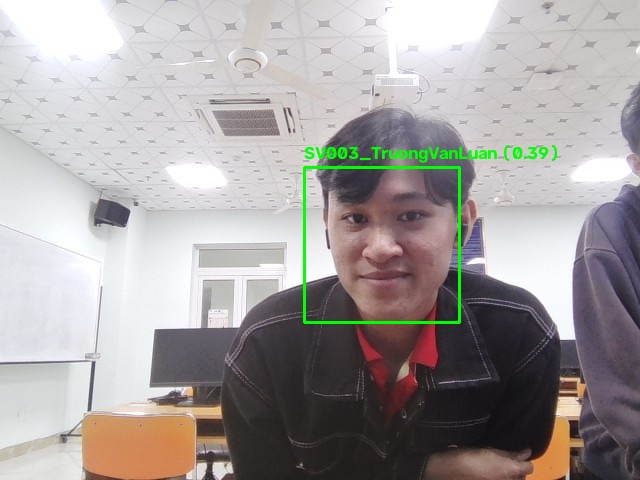


📄 Nội dung file attendance.csv hiện tại:
Tên sinh viên,Thời gian,Khoảng cách Euclid,Ảnh đối chiếu
SV001_TranDinhBaoLong,2026-10-29 08:42:06,0.3620,evidence/20261029_084206_SV001_TranDinhBaoLong.jpg
SV004_NguyenQuocHuy,2026-10-29 08:42:57,0.3933,evidence/20261029_084257_SV004_NguyenQuocHuy.jpg
SV002_NguyenHoangKhiem,2026-10-29 08:48:12,0.4464,evidence/20261029_084812_SV002_NguyenHoangKhiem.jpg
SV003_TruongVanLuan,2026-10-29 08:48:30,0.3930,evidence/20261029_084830_SV003_TruongVanLuan.jpg


📋 TỔNG KẾT HÔM NAY: 4/4 sinh viên đã điểm danh
   ✅ Có mặt: SV001_TranDinhBaoLong, SV002_NguyenHoangKhiem, SV003_TruongVanLuan, SV004_NguyenQuocHuy
   ❌ Vắng mặt: —


In [ ]:
# ============================================================
# CELL 7: Pipeline chính — liveness + nhận diện + điểm danh + tổng kết
# ============================================================
import csv
from datetime import datetime
from pathlib import Path
from IPython.display import Image, display as ipy_display

# ---- 1) Build hoặc Tải DB an toàn ----
db = None
if CFG.database_path.exists():
    try:
        db = FaceDatabase.load(CFG.database_path)
    except Exception as e:
        print(f"⚠️ Phát hiện lỗi khi nạp Database: {e}. Tiến hành xóa và build lại...")
        try:
            CFG.database_path.unlink()
        except Exception:
            pass

if db is None:
    print("⚙️ Đang dựng (build) database từ thư mục dataset...")
    db = FaceDatabase.build(CFG.dataset_dir, detector=CFG.detector_model)
    db.save(CFG.database_path)

# ---- 2) Khởi tạo logger & recognizer ----
logger = AttendanceLogger(CFG.attendance_csv, cooldown_seconds=CFG.cooldown_seconds)
recognizer = FaceRecognizer(db, logger, CFG)

# ---- 3) Chụp chuỗi frame (liveness) & nhận diện ----
print(f"📚 Database hiện tại: {len(db)} embeddings | {len(db.unique_names)} sinh viên")
print("🌐 Một TAB CAMERA RIÊNG sẽ mở — bấm link Colab in ra ở dưới, rồi trong tab đó bấm nút '📷 Bắt đầu điểm danh' và CHỚP MẮT tự nhiên...")

try:
    burst = WebcamCapture().capture_burst()
    demo_path = recognizer.process(burst)
    if demo_path and demo_path.exists():
        ipy_display(Image(str(demo_path)))
    else:
        print("⚠️ Không điểm danh được: không thấy mặt / liveness không đạt / lỗi xử lý ảnh.")
except Exception as webcam_err:
    print(f"❌ Không thể chụp ảnh từ webcam: {webcam_err}")

# ---- 4) Hiển thị kết quả điểm danh CSV ----
if CFG.attendance_csv.exists():
    print("\n📄 Nội dung file attendance.csv hiện tại:")
    print(CFG.attendance_csv.read_text(encoding="utf-8-sig"))

# ---- 5) Tổng kết hôm nay: ai có mặt, ai vắng ----
roster = set(db.unique_names)
seen = set()
if CFG.attendance_csv.exists():
    with open(CFG.attendance_csv, encoding="utf-8-sig", newline="") as f:
        for row in csv.DictReader(f):
            if (row.get("Thời gian") or "").startswith(datetime.now().strftime("%Y-%m-%d")):
                seen.add((row.get("Tên sinh viên") or "").strip())
print(f"\n📋 TỔNG KẾT HÔM NAY: {len(seen & roster)}/{len(roster)} sinh viên đã điểm danh")
print("   ✅ Có mặt:", ", ".join(sorted(seen & roster)) or "—")
print("   ❌ Vắng mặt:", ", ".join(sorted(roster - seen)) or "—")


**Đánh giá độ chính xác (tùy chọn)**

In [ ]:
# ============================================================
# CELL 8: Evaluation — đo Accuracy / Precision / Recall / F1
# ============================================================
# Bắt buộc dùng đúng pipeline như lúc nhận diện thật:
# detect → ALIGN 68 mốc → encoding trên chip 150x150.
# Nếu encode ảnh gốc chưa align thì số đo phản ánh một hệ thống khác → vô nghĩa.
from collections import defaultdict
from typing import Dict, List

class Evaluator:
    """Đánh giá trên thư mục test có nhãn (1 thư mục con / người)."""

    def __init__(self, recognizer: FaceRecognizer):
        self.rec = recognizer

    def evaluate(self, test_dir: Path) -> Dict[str, float]:
        if not test_dir.is_dir():
            print(f"❌ Không tìm thấy thư mục test: {test_dir}")
            return {}

        tp = wrong = undet = 0
        per_class: Dict[str, List[int]] = defaultdict(lambda: [0, 0, 0])  # tp, fp, fn

        for person_dir in sorted(test_dir.iterdir()):
            if not person_dir.is_dir():
                continue
            true_name = person_dir.name
            for img_path in sorted(person_dir.iterdir()):
                if img_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
                    continue

                rgb = face_recognition.load_image_file(str(img_path))
                locs = face_recognition.face_locations(rgb, model=CFG.detector_model)
                if not locs:
                    undet += 1
                    per_class[true_name][2] += 1
                    continue

                # ALIGN giống hệt lúc build DB & lúc điểm danh
                largest = max(locs, key=lambda loc: (loc[2] - loc[0]) * (loc[1] - loc[3]))
                aligned = align_face(rgb, largest)
                encs = face_recognition.face_encodings(aligned, known_face_locations=[(0, 150, 150, 0)])
                if not encs:
                    undet += 1
                    per_class[true_name][2] += 1
                    continue

                pred_name, _ = self.rec._match(encs[0])
                if pred_name == true_name:
                    tp += 1
                    per_class[true_name][0] += 1
                else:
                    # Nhận nhầm (người khác hoặc Unknown): chỉ đếm 1 lần, không đếm cả fp lẫn fn
                    wrong += 1
                    per_class[true_name][1] += 1

        total = tp + wrong + undet
        precision = tp / (tp + wrong) if (tp + wrong) else 0.0
        recall = tp / (tp + undet) if (tp + undet) else 0.0
        f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0.0
        accuracy = tp / total if total else 0.0

        missing = sorted(set(per_class) - set(self.rec.db.names))
        if missing:
            print(f"  ⚠️ Người test không có trong DB (LUÔN bị đếm là nhận sai): {", ".join(missing)}")

        print(f"  Tổng ảnh test: {total}")
        for name, m in sorted(per_class.items()):
            n = m[0] + m[1] + m[2]
            if n:
                print(f"  - {name}: {m[0]}/{n} đúng ({m[0]/n:.0%})")
        print(f"  accuracy : {accuracy:.4f}   (đúng / tổng ảnh)")
        print(f"  precision: {precision:.4f}   (đúng / số ảnh có detect được mặt)")
        print(f"  recall   : {recall:.4f}     (đúng / số ảnh detect được mặt: fn = không detect)")
        print(f"  f1       : {f1:.4f}")
        return {
            "accuracy": accuracy, "precision": precision,
            "recall": recall, "f1": f1,
            "tp": tp, "fp": wrong, "fn": undet,
        }


# Ví dụ chạy (bỏ comment nếu có thư mục test/):
# evaluator = Evaluator(recognizer)
# metrics = evaluator.evaluate(Path("test"))


**Troubleshooting tự động**

In [ ]:
# ============================================================
# CELL 9: Health-check tự động trước khi chạy webcam
# ============================================================
def health_check() -> bool:
    """Kiểm tra mọi thứ sẵn sàng — in báo cáo rõ ràng."""
    issues = []

    # 1) Dataset
    if not CFG.dataset_dir.is_dir():
        issues.append(f"❌ Thiếu thư mục {CFG.dataset_dir}")
    else:
        n_people = sum(1 for p in CFG.dataset_dir.iterdir() if p.is_dir())
        print(f"✅ Dataset: {n_people} sinh viên")

    # 2) Database
    try:
        if CFG.database_path.exists():
            db = FaceDatabase.load(CFG.database_path)
        else:
            db = FaceDatabase.build(CFG.dataset_dir, CFG.detector_model)
            db.save(CFG.database_path)  # build xong lưu luôn — không để CELL 7 phải build lại từ đầu
        print(f"✅ Database: {len(db)} embeddings / {len(db.unique_names)} người")
        if len(db) == 0:
            issues.append("❌ Database rỗng — chưa có ảnh hợp lệ trong dataset/.")
    except Exception as e:
        issues.append(f"❌ Database: {e}")

    # 3) CSV
    if CFG.attendance_csv.exists():
        rows = CFG.attendance_csv.read_text(encoding="utf-8-sig").strip().split("\n")
        print(f"✅ attendance.csv: {len(rows) - 1} bản ghi")
    else:
        print("ℹ️  attendance.csv chưa có — sẽ tự tạo khi chạy.")

    # 4) Model file
    if not Path("shape_predictor_68_face_landmarks.dat").exists():
        issues.append("❌ Thiếu shape_predictor_68_face_landmarks.dat — hãy chạy lại CELL 1")

    if issues:
        print("\n⚠️  CẦN KHẮC PHỤC:")
        for issue in issues:
            print(f"   {issue}")
        return False
    print("\n🎉 Hệ thống sẵn sàng — chạy CELL 7 để điểm danh.")
    return True


health_check()


In [ ]:
# ============================================================
# CELL 10: Reset, Build & Kiểm tra toàn diện hệ thống để chuẩn bị nộp bài
# ============================================================
import os
from pathlib import Path

# Đảm bảo hàm health_check luôn sẵn sàng kể cả khi CELL 9 chưa chạy
if "health_check" not in globals():
    def health_check() -> bool:
        issues = []
        if not CFG.dataset_dir.is_dir():
            issues.append(f"❌ Thiếu thư mục {CFG.dataset_dir}")
        else:
            n_people = sum(1 for p in CFG.dataset_dir.iterdir() if p.is_dir() and not p.name.startswith("."))
            print(f"✅ Dataset: {n_people} sinh viên")

        try:
            if CFG.database_path.exists():
                db = FaceDatabase.load(CFG.database_path)
            else:
                db = FaceDatabase.build(CFG.dataset_dir, CFG.detector_model)
                db.save(CFG.database_path)
            print(f"✅ Database: {len(db)} embeddings / {len(db.unique_names)} người")
            if len(db) == 0:
                issues.append("❌ Database rỗng — chưa có ảnh hợp lệ trong dataset/.")
        except Exception as e:
            issues.append(f"❌ Database: {e}")

        if CFG.attendance_csv.exists():
            rows = CFG.attendance_csv.read_text(encoding="utf-8-sig").strip().split("\n")
            print(f"✅ attendance.csv: {len(rows) - 1} bản ghi")
        else:
            print("ℹ️  attendance.csv chưa có — sẽ tự tạo khi chạy.")

        if not Path("shape_predictor_68_face_landmarks.dat").exists():
            issues.append("❌ Thiếu shape_predictor_68_face_landmarks.dat — hãy chạy lại CELL 1")

        if issues:
            print("\n⚠️  CẦN KHẮC PHỤC:")
            for issue in issues:
                print(f"   {issue}")
            return False
        print("\n🎉 Hệ thống sẵn sàng — chạy CELL 7 để điểm danh.")
        return True

print("🧹 Bước 1: Khởi động lại và xóa file DB cũ để rebuild an toàn...")
db_path = Path("known_faces.pkl")
if db_path.exists():
    db_path.unlink()

print("⚙️ Bước 2: Build Database mới sử dụng 68-landmark Face Alignment...")
try:
    db = FaceDatabase.build(CFG.dataset_dir, detector=CFG.detector_model)
    db.save(CFG.database_path)
    print(f"✅ Đã xây dựng Database thành công! {len(db.unique_names)} sinh viên / {len(db)} embeddings.")
except Exception as e:
    print(f"❌ Lỗi khi xây dựng Database: {e}")

print("\n🔍 Bước 3: Đang chạy lại Health Check...")
health_check()

print("\n📄 Bước 4: Kiểm tra lịch sử nhật ký 'attendance.csv' thực tế:")
csv_path = Path("attendance.csv")
if csv_path.exists():
    print(csv_path.read_text(encoding="utf-8-sig"))
else:
    print("❌ File attendance.csv chưa được khởi tạo. Hãy thực hiện điểm danh ở CELL 7 để tự sinh nhật ký.")
